In [ ]:
# # test_file_name = "fixedTest4.txt"
# test_file_name = "test1.txt"
# testing = True

In [ ]:
# from pathlib import Path
# import sys

# # --- Path Calculations ---

# SCRIPT_DIR = Path(sys.argv[0]).resolve().parent.parent.parent
# PROJECT_ROOT = SCRIPT_DIR.parent.parent


# # Define the directory containing 'keymaerax_parser.py' and 'ast_config.py'
# # (e.g., 'project_root/AST_parser/')

# parser_module_dir = PROJECT_ROOT / "kyx_parser"
# src_dir = parser_module_dir / "AST_parser"

# # Add the parser module directory to Python's system path
# if str(parser_module_dir) not in sys.path:
#     sys.path.insert(0, str(parser_module_dir))
#     print(f"Added '{parser_module_dir}' to sys.path.")
# else:
#     print(f"'{parser_module_dir}' already in sys.path.")

# # Define test input and expected output directories relative to SCRIPT_DIR
# # Based on the file explorer, 'input' and 'output_AST' are direct subdirectories of 'test'.
# TEST_INPUT_DIR = parser_module_dir / "test" / "input" / "withBound"

# # --- Debugging prints for paths ---
# print(f"Project Root: {PROJECT_ROOT.resolve()}")
# print(f"Script Directory: {SCRIPT_DIR.resolve()}")
# print(f"Parser Module Directory: {src_dir.resolve()}")
# print(f"Test Input Directory: {TEST_INPUT_DIR.resolve()}")

# # --- How to get the content of test1.txt ---

# # 1. Construct the full path to test1.txt
# test_path = TEST_INPUT_DIR / test_file_name
# content = None

# print(f"\nAttempting to read: {test_path.resolve()}")

# # 2. Read the content of the file
# try:
#     # Use 'with open(...)' for safe file handling (ensures file is closed)
#     with open(test_path, 'r', encoding='utf-8') as f:
#         content = f.read()
#     print(f"Successfully read '{test_file_name}'. Content length: {len(content)} characters.")
#     print(f"Content preview (first 200 chars):\n{content}")  # Print a preview of the content

# except FileNotFoundError:
#     print(f"Error: The file '{test_path.resolve()}' was not found.")
#     print("Please ensure the file exists at the specified path relative to your project root.")
# except Exception as e:
#     print(f"An unexpected error occurred while reading the file: {e}")

Added 'D:\Reinforcement learning\kyx_parser' to sys.path.
Project Root: D:\Reinforcement learning
Script Directory: D:\Reinforcement learning\kyx_parser\.venv
Parser Module Directory: D:\Reinforcement learning\kyx_parser\AST_parser
Test Input Directory: D:\Reinforcement learning\kyx_parser\test\input\withBound

Attempting to read: D:\Reinforcement learning\kyx_parser\test\input\withBound\test1.txt
Successfully read 'test1.txt'. Content length: 4873 characters.
Content preview (first 200 chars):
Theorem "IJRR17/Theorem 1: Static safety"

Definitions
  // Physical Constants
  // @const: bound=[0.1:0.5], def="time limit for control decisions"
  Real ep; 
  // @const: bound=[0.5:5.0], def="minimum braking capability of the robot"
  Real b;       
  // @const: bound=[1.0:10.0], def="maximum acceleration"
  Real A;       
  // @const: bound=[0.1:1.0], def="maximum steering (rotational velocity)"
  Real W;       

  // Distance Calculations
  Real stopDist(Real v) = v^2 / (2*b);
  Real accelC

In [ ]:
# # PyAST_test.py
# from keymaerax_parser import KeYmaeraXParser, convert_keymaerax_ast_to_intermediate_pyast
# from gym_generator import generate_gym_environment_code # Import the generator

# # --- KeYmaera X Input ---


# # --- Main Execution ---
# if __name__ == "__main__":
#     print("--- Parsing KeYmaera X Input into internal AST ---")
#     parser = KeYmaeraXParser(content)
#     kx_ast = parser.parse()
#     # Print the internal KeYmaera X AST for debugging/verification
#     print(kx_ast) # Commented out for brevity

#     print("\n--- Converting KeYmaera X AST to Intermediate Python AST ---")
#     py_ast_config = convert_keymaerax_ast_to_intermediate_pyast(kx_ast)
#     print("Intermediate Python AST (GymEnvironmentConfig):\n", py_ast_config)

#     print("\n--- Generating Gymnasium environment code ---")
#     if testing:
#         generated_code = generate_gym_environment_code(py_ast_config, envName="GeneratedKXEnv")
#     else:
#         generated_code = generate_gym_environment_code(py_ast_config)

#     # print(generated_code)
#     output_filename = "generated_kx_env.py"
#     with open(src_dir / output_filename, "w") as f:
#         f.write(generated_code)

#     print(f"Generated Gymnasium environment code saved to {output_filename}")

--- Parsing KeYmaera X Input into internal AST ---
[KeYmaeraXSpecification]:
  [TheoremName]: IJRR17/Theorem 1: Static safety
  [DefinitionsBlock]:
    [DEF]: Real ep [Meta: {'type': 'const', 'bound': '0.1:0.5', 'def': 'time limit for control decisions'}]
    [DEF]: Real b [Meta: {'type': 'const', 'bound': '0.5:5.0', 'def': 'minimum braking capability of the robot'}]
    [DEF]: Real A [Meta: {'type': 'const', 'bound': '1.0:10.0', 'def': 'maximum acceleration'}]
    [DEF]: Real W [Meta: {'type': 'const', 'bound': '0.1:1.0', 'def': 'maximum steering (rotational velocity)'}]
    [DEF]: Real stopDist = v^2 / (2*b)
      [Parameters]: Real v
    [DEF]: Real accelComp = ((A/b + 1) * (A/2 * ep^2 + ep*v))
      [Parameters]: Real v
    [DEF]: Real admissibleSeparation = stopDist(v) + accelComp(v)
      [Parameters]: Real v
    [DEF]: Bool isWellformedDir = dx^2 + dy^2 = 1 [Meta: {'type': 'progress', 'reward': '10', 'shape': '-((dx**2 + dy**2) - 1)**2', 'on_success': {'action': 'continue', 'sta

# Basic testing

In [1]:
import gymnasium as gym
# The class name is derived from the Theorem name: "IJRR17/Theorem 1: Static safety"
# spaces, slashes, colons, etc., are replaced with underscores.
from manual_kx_env_for_test_4 import GeneratedKXEnv
import numpy as np

# Instantiate the environment
env = GeneratedKXEnv()

observation, info = env.reset()
print("Initial observation:", observation)
print("Observation Space:", env.observation_space)
print("Action Space:", env.action_space)

# Example 1: Choose the first branch: Obstacle movement (index 0 for ChoiceLevel_0)
# Requires 'assign_vxo' and 'assign_vyo'
action_branch_0 = {
    'choice_ChoiceLevel_0': 0, # Select the obstacle movement branch (index 0)
    'assign_vxo': 0.1,         # Example value for vxo (constrained by V)
    'assign_vyo': 0.2,         # Example value for vyo (constrained by V)
    'choice_ChoiceLevel_1': 0, # Dummy value for unused nested choice
    'assign_v': 0.0,           # Dummy value for unused nondeterministic assignments
    'assign_w': 0.0,
    'assign_r': 0.0,
    'assign_xo': 0.0,
    'assign_yo': 0.0,
    
}

print("\nTaking 5 steps with action_branch_0 (obstacle movement):")
for i in range(5):
    observation, reward, terminated, truncated, info = env.step(action_branch_0)
    print(f"Step {i+1}: Obs={observation}, Reward={reward:.2f}, Terminated={terminated}, Truncated={truncated}")
    if terminated or truncated:
        print("Episode finished.")
        break
env.close()

# # Example 2: Reset and choose the agent movement branch (index 1 for ChoiceLevel_0)
# # Then, within agent movement, choose the 'agent moves' sub-branch (index 1 for ChoiceLevel_1)
# print("\nResetting environment and taking 5 steps with action_branch_2 (agent moves):")
# observation, info = env.reset()

# action_branch_2 = {
#     'choice_ChoiceLevel_0': 1, # Select the agent movement branch (index 1)
#     'choice_ChoiceLevel_1': 1, # Select the agent *moving* sub-branch (index 1 within ChoiceLevel_1)
#     'assign_vxo': 0.0,         # Dummy value for unused obstacle assignment
#     'assign_vyo': 0.0,         # Dummy value for unused obstacle assignment
#     'assign_v': 1.0,           # Example value for v (must be >= 0)
#     'assign_w': 0.1,           # Example value for w (within -W to W, assuming W=0.5)
#     'assign_r': 10.0,          # Example value for r (r != 0 and r*w == v) - make sure this holds!
#                                # Here: 10.0 * 0.1 = 1.0, so r*w == v is satisfied.
#     'assign_xo': 10.0,         # Example value for xo
#     'assign_yo': 0.0,          # Example value for yo
# }

# for i in range(5):
#     observation, reward, terminated, truncated, info = env.step(action_branch_2)
#     print(f"Step {i+1}: Obs={observation}, Reward={reward:.2f}, Terminated={terminated}, Truncated={truncated}")
#     if terminated or truncated:
#         print("Episode finished.")
#         break

# env.close()

# # Example 3: Reset and choose the agent movement branch (index 1 for ChoiceLevel_0)
# # Then, within agent movement, choose the 'agent stops' sub-branch (index 0 for ChoiceLevel_1)
# print("\nResetting environment and taking 5 steps with action_branch_3 (agent stops):")
# observation, info = env.reset()

# action_branch_3 = {
#     'choice_ChoiceLevel_0': 1, # Select the agent movement branch (index 1)
#     'choice_ChoiceLevel_1': 0, # Select the agent *stops* sub-branch (index 0 within ChoiceLevel_1)
#     'assign_vxo': 0.0,         # Dummy value for unused obstacle assignment
#     'assign_vyo': 0.0,         # Dummy value for unused obstacle assignment
#     'assign_v': 0.0,           # Dummy value, as v will be set to 0 by deterministic assignment
#     'assign_w': 0.0,           # Dummy value, as w will be set to 0 by deterministic assignment
#     'assign_r': 0.0,           # Dummy value for unused nondeterministic assignments
#     'assign_xo': 0.0,
#     'assign_yo': 0.0,
# }

# for i in range(5):
#     observation, reward, terminated, truncated, info = env.step(action_branch_3)
#     print(f"Step {i+1}: Obs={observation}, Reward={reward:.2f}, Terminated={terminated}, Truncated={truncated}")
#     if terminated or truncated:
#         print("Episode finished.")
#         break

# env.close()

DEBUG_CISB: Expanding KeYmaera X expression for Z3 conversion: assumptions(xr, vr, xg, T)
DEBUG_CISB: Expanded KeYmaera X expression: ((((((A > 0) & (b > 0)) & (ep > 0)) & (Vmax >= ((2 * A) * ep))) & (GDelta > ((Vmax * ep) + ((Vmax ^ 2) / (2 * b))))) & (((vr = 0) & (xr < (xg - GDelta))) & (T > (((ep + (((xg - xr) - GDelta) / (A * ep))) + ep) + (Vmax / b)))))
DEBUG_CISB: Expanding KeYmaera X expression for Z3 conversion: assumptions(xr, vr, xg, T)
DEBUG_CISB: Expanded KeYmaera X expression: ((((((A > 0) & (b > 0)) & (ep > 0)) & (Vmax >= ((2 * A) * ep))) & (GDelta > ((Vmax * ep) + ((Vmax ^ 2) / (2 * b))))) & (((vr = 0) & (xr < (xg - GDelta))) & (T > (((ep + (((xg - xr) - GDelta) / (A * ep))) + ep) + (Vmax / b)))))
Initial observation: [-99.99351    0.       -11.366027 -62.890358   0.         2.      ]
Observation Space: Box(-inf, inf, (6,), float32)
Action Space: Dict('choice_ChoiceLevel_0': Discrete(4))

Taking 5 steps with action_branch_0 (obstacle movement):
Step 1: Obs=[-99.99351    

# Testing the plotting

In [2]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
# Import your generated environment class
from generated_kx_env import GeneratedKXEnv

# Optional: Set debug_mode to True in the environment for more verbose plotting output
# This can be done after instantiation, or by modifying the __init__ if you want it always on.

def run_and_plot_episode(env, episode_num=0):
    print(f"\n--- Running Episode {episode_num} ---")
    observation, info = env.reset()
    print(f"Initial State (from reset): {env.state}")
    print(f"Initial Observation: {observation}")

    terminated = False
    truncated = False
    total_reward = 0.0
    step_count = 0

    # Run for a maximum of 100 steps or until termination/truncation
    max_steps = 100
    while not terminated and not truncated and step_count < max_steps:
        # For testing, we'll use a dummy action.
        # In a real scenario, this would come from a policy or agent.
        # The action space for GeneratedKXEnv is a Dict.
        # We need to provide values for 'choice_ChoiceLevel_0', 'assign_w', 'assign_r', 'assign_xo', 'assign_yo'.
        # Let's pick the first choice (index 0) and random values for assignments.
        action = {
            'choice_ChoiceLevel_0': 0, # Corresponds to the first SequenceActionConfig (a = -b)
            'assign_w': env.np_random.uniform(-1.0, 1.0),
            'assign_r': env.np_random.uniform(0.1, 10.0), # r cannot be 0
            'assign_xo': env.np_random.uniform(-10.0, 10.0),
            'assign_yo': env.np_random.uniform(-10.0, 10.0),
        }
        # Note: The specific values for assign_w, assign_r, assign_xo, assign_yo might not be used
        # if the chosen action (choice_ChoiceLevel_0) doesn't involve NondeterministicAssignmentActionConfig for them.
        # For choice_ChoiceLevel_0 = 0, only 'a' is deterministically assigned.
        # To test nondeterministic assignments, you'd need to pick choice_ChoiceLevel_0 = 2.
        # Let's try choice_ChoiceLevel_0 = 2 for one episode to see nondeterministic assignments.
        if episode_num % 2 == 1: # Alternate choices for demonstration
            action['choice_ChoiceLevel_0'] = 2 # This choice uses assign_w, assign_r, assign_xo, assign_yo

        observation, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        step_count += 1

        # print(f"Step {step_count}: Obs={observation[:3]}, Reward={reward:.2f}, Terminated={terminated}, Truncated={truncated}")
        # print(f"  Current State: {env.state}")

        if terminated or truncated:
            print(f"Episode finished after {step_count} steps. Total Reward: {total_reward:.2f}")
            print(f"Final State: {env.state}")
            break
    else:
        print(f"Episode finished after {step_count} steps (max_steps reached). Total Reward: {total_reward:.2f}")
        print(f"Final State: {env.state}")


    # After the episode, plot the state history
    print("Generating plot for the finished episode...")
    env.render(mode="matplotlib")
    print("Plot generated. Close the plot window to continue.")

#Smart agent

DEBUG_INIT: Deserialization successful.
DEBUG_INIT: Type of self.config: <class 'pyast_config.GymEnvironmentConfig'>
DEBUG_INIT: self.config.problem: [ProblemConfig]
  [Precondition]: 'assumptions(xr, vr, xg, T)'
  [LoopExecution]
    [Iterations]: 'inf'
    [LoopInvariant]: 'loopinv(xr, vr, xg, T)'
    [LoopBody]:
      [SequenceAction]
        [SequenceAction]
          [CallHybridProgram]: controlFunc
          [DeterministicAssignment]: t := '0'
        [HybridProgramStep]: stepFunc @invariant(t>=0)
  [Postcondition]: 'ensure(xr, vr, xg)'
DEBUG_INIT: Type of self.config.problem: <class 'pyast_config.ProblemConfig'>
DEBUG_INIT: self.config.problem.loop_execution: LoopExecutionConfig(loop_invariant_formula='loopinv(xr, vr, xg, T)', iterations='inf', loop_body=[SequenceAction]
  [SequenceAction]
    [CallHybridProgram]: controlFunc
    [DeterministicAssignment]: t := '0'
  [HybridProgramStep]: stepFunc @invariant(t>=0))
DEBUG_INIT: Type of self.config.problem.loop_execution: <class 'p

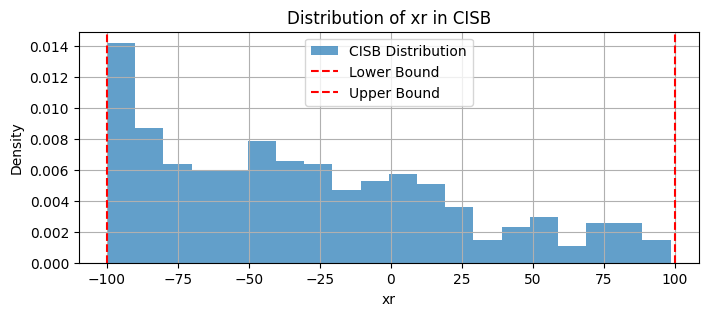

  Variable 'vr' (Range: [-100.0000, 100.0000]):
    Min: 0.0000, Max: 0.0000
    Mean: 0.0000, Std Dev: 0.0000
    Range coverage: 0.00% (min_offset_ratio: 0.50, max_offset_ratio: 0.50)


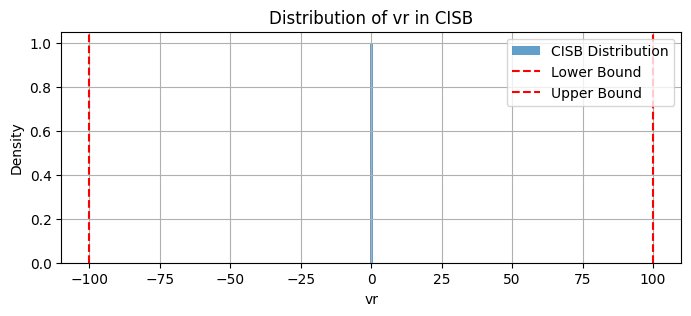

  Variable 'ar' (Range: [-100.0000, 100.0000]):
    Min: -99.3397, Max: 99.9478
    Mean: 3.0958, Std Dev: 54.9894
    Range coverage: 99.64% (min_offset_ratio: 0.00, max_offset_ratio: 0.00)


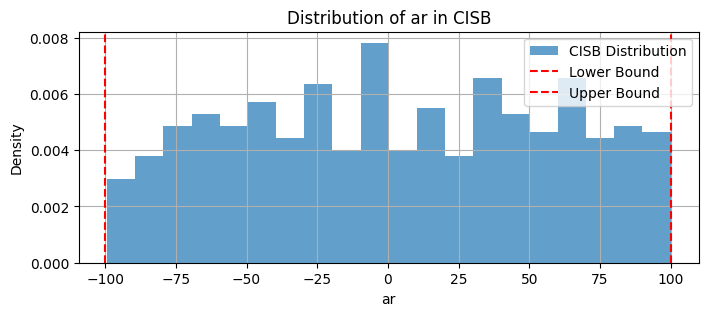

  Variable 'xg' (Range: [-100.0000, 100.0000]):
    Min: -96.8325, Max: 100.0000
    Mean: 24.0509, Std Dev: 52.4782
    Range coverage: 98.42% (min_offset_ratio: 0.02, max_offset_ratio: 0.00)


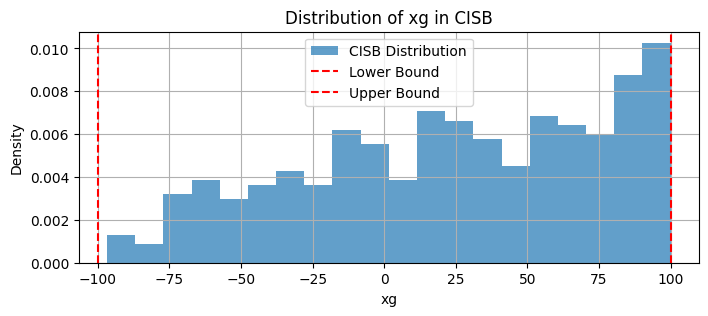

  Variable 't' (Range: [-100.0000, 100.0000]):
    Min: 0.0000, Max: 0.0000
    Mean: 0.0000, Std Dev: 0.0000
    Range coverage: 0.00% (min_offset_ratio: 0.50, max_offset_ratio: 0.50)


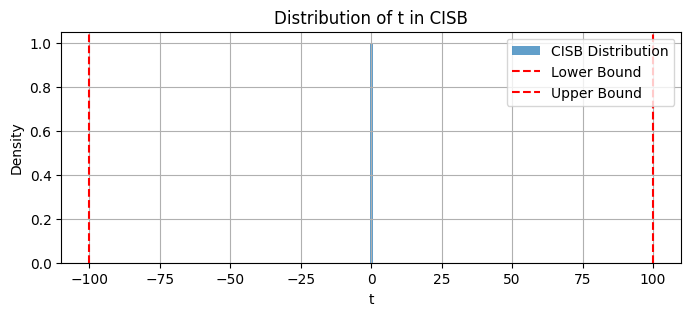

  Variable 'T' (Range: [-100.0000, 100.0000]):
    Min: 0.0000, Max: 100.0000
    Mean: 39.4619, Std Dev: 35.3274
    Range coverage: 50.00% (min_offset_ratio: 0.50, max_offset_ratio: 0.00)


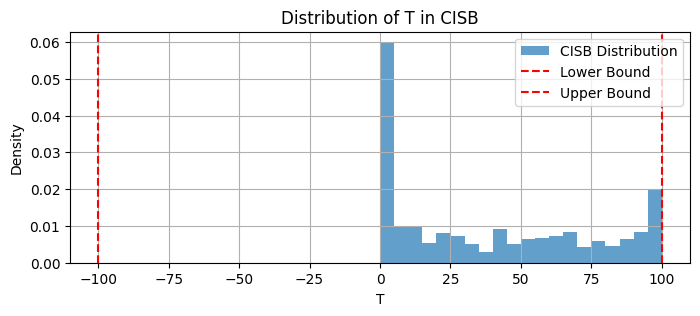

  Variable 'ep' (Range: [-100.0000, 100.0000]):
    Min: 0.0000, Max: 49.5000
    Mean: 2.5905, Std Dev: 8.0877
    Range coverage: 24.75% (min_offset_ratio: 0.50, max_offset_ratio: 0.25)


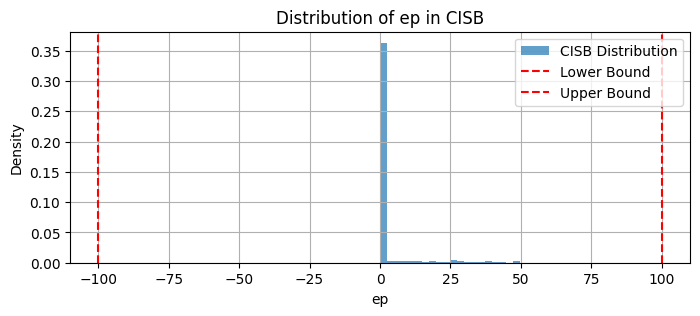

  Variable 'b' (Range: [-100.0000, 100.0000]):
    Min: 0.0000, Max: 99.7500
    Mean: 35.1510, Std Dev: 32.8950
    Range coverage: 49.87% (min_offset_ratio: 0.50, max_offset_ratio: 0.00)


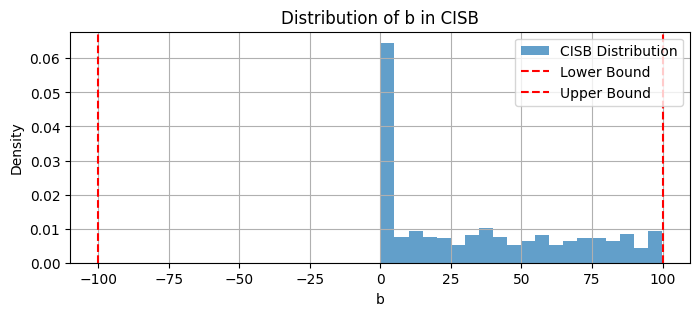

  Variable 'A' (Range: [-100.0000, 100.0000]):
    Min: 0.0000, Max: 99.9800
    Mean: 31.6202, Std Dev: 33.9518
    Range coverage: 49.99% (min_offset_ratio: 0.50, max_offset_ratio: 0.00)


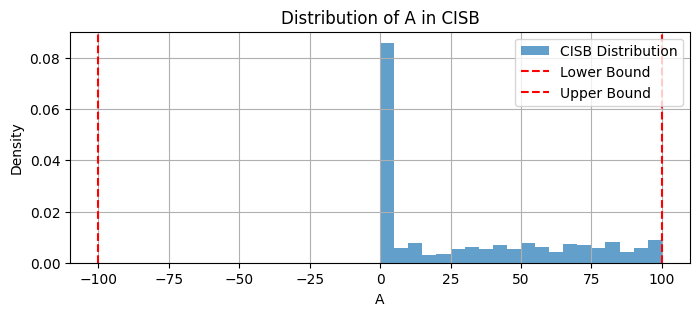

  Variable 'GDelta' (Range: [-100.0000, 100.0000]):
    Min: 0.0000, Max: 100.0000
    Mean: 42.0813, Std Dev: 34.0097
    Range coverage: 50.00% (min_offset_ratio: 0.50, max_offset_ratio: 0.00)


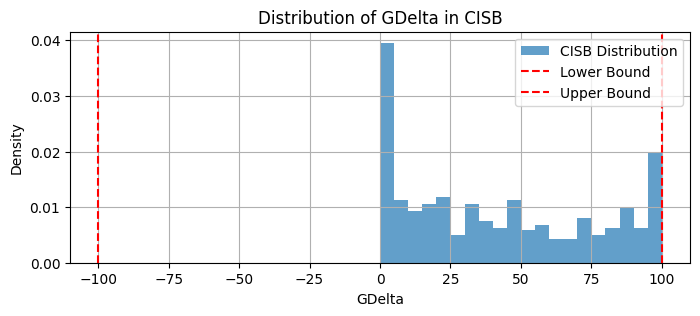

  Variable 'Vmax' (Range: [-100.0000, 100.0000]):
    Min: 0.0000, Max: 98.3766
    Mean: 21.1702, Std Dev: 29.0125
    Range coverage: 49.19% (min_offset_ratio: 0.50, max_offset_ratio: 0.01)


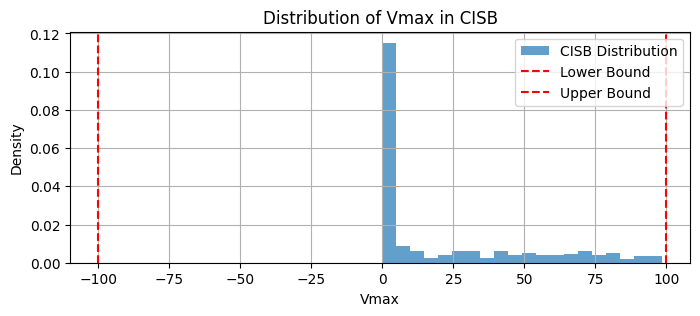


2. Diversity based on Dynamic Bounding Boxes (from predicate metadata):
  No dynamic bounding box definitions found in predicate metadata.
DEBUG_CISB: Populating Contrastive Initial State Buffer (CISB) with 500 diverse states using Z3.Optimize...
DEBUG_CISB: Warning: Could not parse bound string '0.1:0.5' for constant 'ep'. Using default range (-100.0, 100.0).
DEBUG_CISB: Warning: Could not parse bound string '0.5:5.0' for constant 'b'. Using default range (-100.0, 100.0).
DEBUG_CISB: Warning: Could not parse bound string '1.0:10.0' for constant 'A'. Using default range (-100.0, 100.0).
DEBUG_CISB: Warning: Could not parse bound string '1.0:10.0' for constant 'GDelta'. Using default range (-100.0, 100.0).
DEBUG_CISB: Warning: Could not parse bound string '5.0:30.0' for constant 'Vmax'. Using default range (-100.0, 100.0).
DEBUG_CISB: Precondition formula for CISB population: assumptions(xr, vr, xg, T)
DEBUG_CISB: Expanding KeYmaera X expression for Z3 conversion: assumptions(xr, vr, x

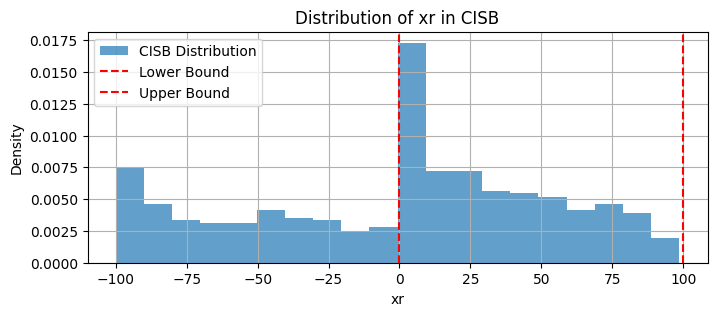

  Variable 'vr' (Range: [0.0000, 20.0000]):
    Min: 0.0000, Max: 0.0000
    Mean: 0.0000, Std Dev: 0.0000
    Range coverage: 0.00% (min_offset_ratio: 0.00, max_offset_ratio: 1.00)


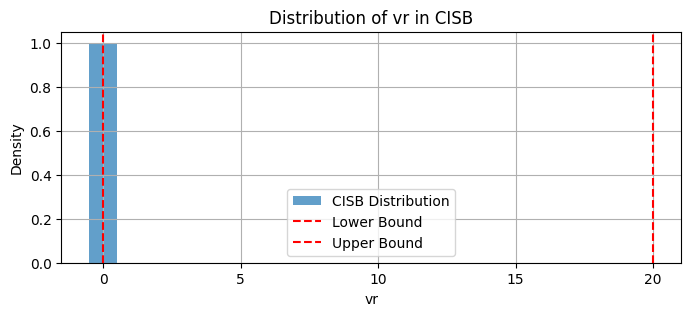

  Variable 'ar' (Range: [-10.0000, 10.0000]):
    Min: -99.3397, Max: 99.9478
    Mean: 1.7995, Std Dev: 40.2517
    Range coverage: 996.44% (min_offset_ratio: -4.47, max_offset_ratio: -4.50)


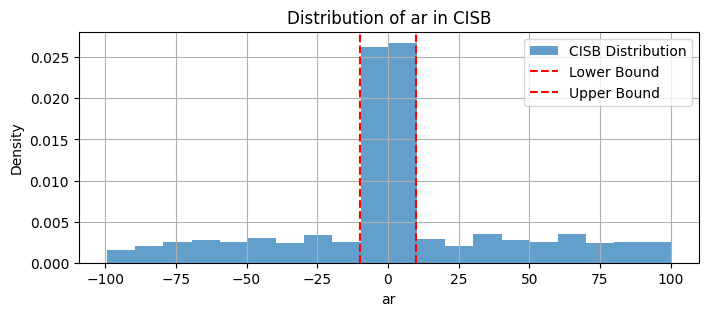

  Variable 'xg' (Range: [0.0000, 100.0000]):
    Min: -96.8325, Max: 100.0000
    Mean: 40.5177, Std Dev: 45.7579
    Range coverage: 196.83% (min_offset_ratio: -0.97, max_offset_ratio: 0.00)


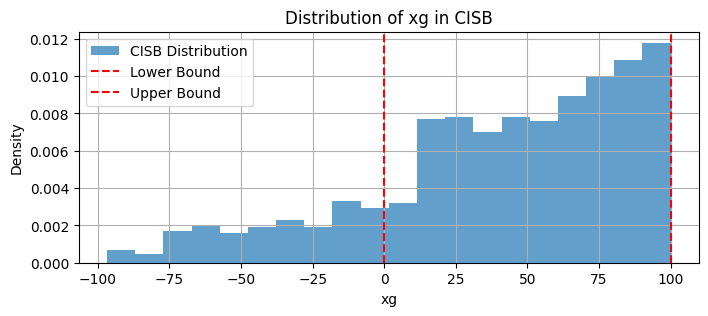

  Variable 't' (Range: [0.0000, 1.0000]):
    Min: 0.0000, Max: 0.0000
    Mean: 0.0000, Std Dev: 0.0000
    Range coverage: 0.00% (min_offset_ratio: 0.00, max_offset_ratio: 1.00)


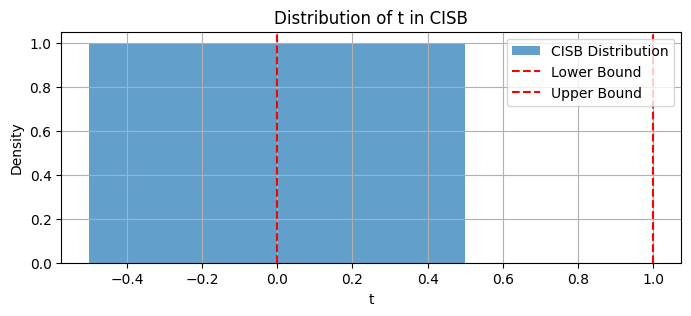

  Variable 'T' (Range: [0.0000, 1000.0000]):
    Min: 0.0000, Max: 998.7447
    Mean: 249.3265, Std Dev: 301.7481
    Range coverage: 99.87% (min_offset_ratio: 0.00, max_offset_ratio: 0.00)


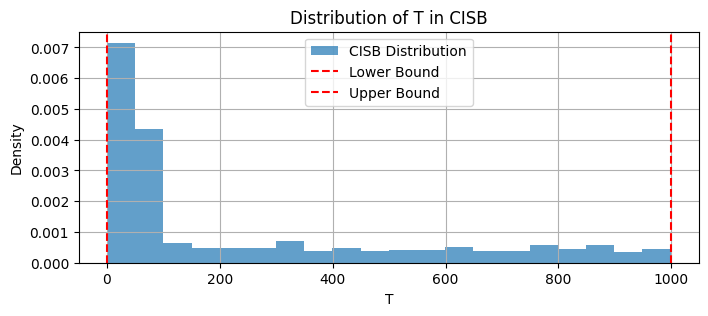

  Variable 'ep' (Range: [0.1000, 0.5000]):
    Min: 0.0000, Max: 49.5000
    Mean: 1.5068, Std Dev: 6.0006
    Range coverage: 12375.00% (min_offset_ratio: -0.25, max_offset_ratio: -122.50)


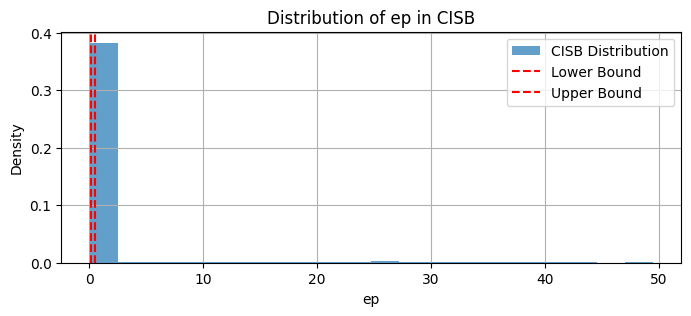

  Variable 'b' (Range: [0.5000, 5.0000]):
    Min: 0.0000, Max: 99.7500
    Mean: 20.2795, Std Dev: 28.6996
    Range coverage: 2216.67% (min_offset_ratio: -0.11, max_offset_ratio: -21.06)


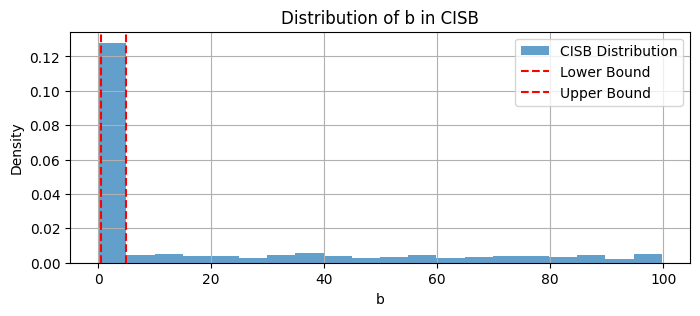

  Variable 'A' (Range: [1.0000, 10.0000]):
    Min: 0.0000, Max: 99.9800
    Mean: 19.2368, Std Dev: 28.0572
    Range coverage: 1110.89% (min_offset_ratio: -0.11, max_offset_ratio: -10.00)


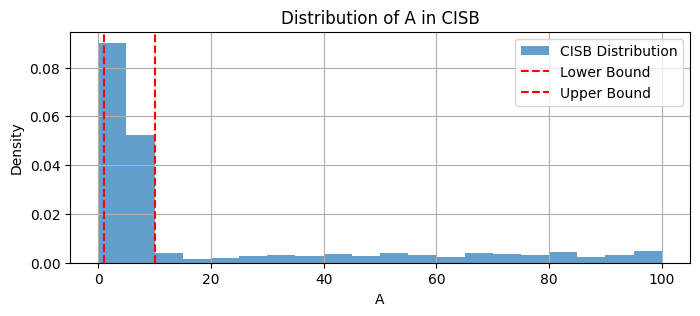

  Variable 'GDelta' (Range: [1.0000, 10.0000]):
    Min: 0.0000, Max: 100.0000
    Mean: 25.9038, Std Dev: 30.1678
    Range coverage: 1111.11% (min_offset_ratio: -0.11, max_offset_ratio: -10.00)


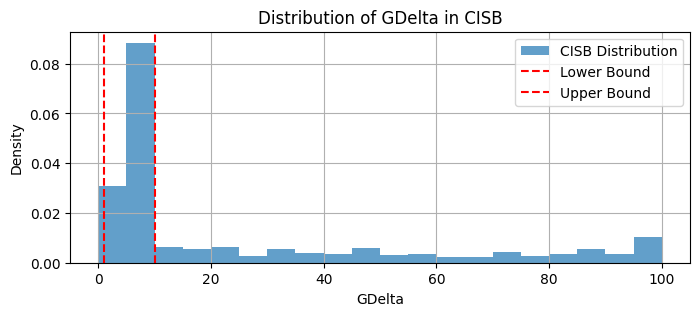

  Variable 'Vmax' (Range: [5.0000, 30.0000]):
    Min: 0.0000, Max: 98.3766
    Mean: 13.9773, Std Dev: 22.4684
    Range coverage: 393.51% (min_offset_ratio: -0.20, max_offset_ratio: -2.74)


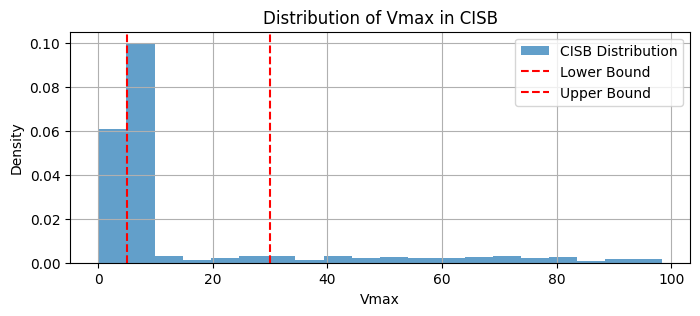


2. Diversity based on Dynamic Bounding Boxes (from predicate metadata):
  No dynamic bounding box definitions found in predicate metadata.
DEBUG_RESET: Initial state: xr=-9.451457, vr=0.000000, ar=-58.683914, xg=89.208871, t=0.000000, T=67.528307, ep=1.500000
DEBUG_RESET: Initial constants: A=0.664062, b=34.951550, ep=1.500000
DEBUG_RESET: Initial state: xr=-81.262385, vr=0.000000, ar=14.118113, xg=-14.392519, t=0.000000, T=44.016814, ep=0.125000
DEBUG_RESET: Initial constants: A=19.401996, b=38.368500, ep=0.125000
--- Environment Information ---
Initial observation: [-81.26238    0.        14.118113 -14.392519   0.        44.016815]
Observation Space: Box(-inf, inf, (6,), float32)
Action Space: Dict('choice_ChoiceLevel_0': Discrete(4))
Initial State Info: {'xr': -81.26238456987849, 'vr': 0.0, 'ar': 14.118112854975081, 'xg': -14.392518679895687, 't': 0.0, 'T': 44.01681355621781}
Environment Constants (from CISB): A=19.40, b=38.37, ep=0.12, GDelta=3.04, Vmax=8.00

--- User's Test: Taki

In [2]:
import gymnasium as gym
from manual_kx_env_for_test_4 import GeneratedKXEnv
import numpy as np
import random # For the agent's random choices

# --- Environment Setup and Testing ---

# Initialize the environment ONLY ONCE
env = GeneratedKXEnv(debug_mode=True)

# --- Initial Environment Info ---
observation, info = env.reset()
print("--- Environment Information ---")
print(f"Initial observation: {observation}")
print(f"Observation Space: {env.observation_space}")
print(f"Action Space: {env.action_space}")
print(f"Initial State Info: {env._get_info()}")

print(f"Environment Constants (from CISB): A={env.constants['A']:.2f}, b={env.constants['b']:.2f}, ep={env.constants['ep']:.2f}, GDelta={env.constants['GDelta']:.2f}, Vmax={env.constants['Vmax']:.2f}")


# Example 1: Choose the first branch: { ar := -b; } (index 0)
print("\n--- User's Test: Taking 5 steps with action_branch_0 (ar := -b;) ---")
# Reset environment for this test block
observation, info = env.reset()
print(f"Initial observation: {observation}, Initial state: {env._get_info()}")
print(f"Constants for this test: A={env.constants['A']:.2f}, b={env.constants['b']:.2f}, ep={env.constants['ep']:.2f}, GDelta={env.constants['GDelta']:.2f}, Vmax={env.constants['Vmax']:.2f}")


for i in range(5):
    action_branch_0 = {
        'choice_ChoiceLevel_0': 0, # Select the first branch: xr > waypointStartDist(xg) then ar := -b
    }
    print(f"Agent chose action: {action_branch_0}")
    observation, reward, terminated, truncated, info = env.step(action_branch_0)
    print(f"Step {i+1}: Obs={observation}, Reward={reward:.2f}, Terminated={terminated}, Truncated={truncated}")
    if terminated or truncated:
        print("Episode finished.")
        break
# No need to env.close() here, as we'll reuse the env object


# Example 2: Reset and choose the third branch: { ar := A; } (index 2)
print("\n--- User's Test: Resetting environment and taking 5 steps with action_branch_2 (ar := A; etc.) ---")
# Reset the existing environment instance
observation, info = env.reset()

print(f"Initial observation: {observation}, Initial state: {env._get_info()}")
print(f"Constants for this test: A={env.constants['A']:.2f}, b={env.constants['b']:.2f}, ep={env.constants['ep']:.2f}, GDelta={env.constants['GDelta']:.2f}, Vmax={env.constants['Vmax']:.2f}")


# Define action_branch_2
action_branch_2 = {
    'choice_ChoiceLevel_0': 2, # Select the third branch
}

for i in range(5):
    print(f"Agent chose action: {action_branch_2}")
    observation, reward, terminated, truncated, info = env.step(action_branch_2)
    print(f"Step {i+1}: Obs={observation}, Reward={reward:.2f}, Terminated={terminated}, Truncated={truncated}")
    if terminated or truncated:
        print("Episode finished.")
        break
# No need to env.close() here, as we'll reuse the env object


# --- Testing with a Generic Random Agent ---
print("\n--- Testing with a Generic Random Agent ---")
# Reuse the existing environment instance
# env = GeneratedKXEnv(debug_mode=True) # REMOVED: No need to re-instantiate

num_episodes = 10
max_steps_per_episode = 100
total_successful_episodes = 0
total_steps_taken = 0

for episode in range(num_episodes):
    print(f"\n--- Episode {episode + 1}/{num_episodes} ---")
    observation, info = env.reset() # Just reset the existing environment

    print(f"Initial Obs: {np.round(observation, 2)}, Initial State: {env._get_info()}")
    print(f"Constants for this episode: A={env.constants['A']:.2f}, b={env.constants['b']:.2f}, ep={env.constants['ep']:.2f}, GDelta={env.constants['GDelta']:.2f}, Vmax={env.constants['Vmax']:.2f}")

    episode_steps = 0
    for step in range(max_steps_per_episode):
        action = {'choice_ChoiceLevel_0': random.randint(0, 3)}
        observation, reward, terminated, truncated, info = env.step(action)
        episode_steps += 1
        total_steps_taken += 1

        if terminated or truncated:
            print(f"  Episode {episode + 1} finished at step {step + 1}. Reason: {'Terminated' if terminated else 'Truncated'}.")
            if not terminated and not truncated:
                 total_successful_episodes += 1
            break
    else:
        print(f"  Episode {episode + 1} completed {max_steps_per_episode} steps without terminating or truncating.")
        total_successful_episodes += 1

# Close the environment only once at the very end of the script
env.close()

print("\n--- Simulation Summary ---")
print(f"Total Episodes Run: {num_episodes}")
print(f"Episodes Completed (not terminated/truncated within max_steps): {total_successful_episodes}")
print(f"Total Steps Across All Episodes: {total_steps_taken}")

#Clueless agent

DEBUG_CISB: Expanding KeYmaera X expression for Z3 conversion: assumptions(xr, vr, xg, T)
DEBUG_CISB: Expanded KeYmaera X expression: ((((((A > 0) & (b > 0)) & (ep > 0)) & (Vmax >= ((2 * A) * ep))) & (GDelta > ((Vmax * ep) + ((Vmax ^ 2) / (2 * b))))) & (((vr = 0) & (xr < (xg - GDelta))) & (T > (((ep + (((xg - xr) - GDelta) / (A * ep))) + ep) + (Vmax / b)))))
--- Environment Information ---
Initial observation: [-31.19961    0.       -92.147644  67.49541    0.        22.692133]
Observation Space: Box(-inf, inf, (6,), float32)
Action Space: Dict('choice_ChoiceLevel_0': Discrete(4))
Initial State Info: {'xr': -31.199609878289923, 'vr': 0.0, 'ar': -92.14764207463774, 'xg': 67.49540608036614, 't': 0.0, 'T': 22.692132028671356}

--- Training with LearningAgent ---
Info: No continuous action spaces found in the environment's action_space Dict.
Episode 1/10, Steps: 3, Total Reward: -100.00, Avg Reward (last 100): -100.00
Episode 2/10, Steps: 6, Total Reward: 1000.00, Avg Reward (last 100): 450

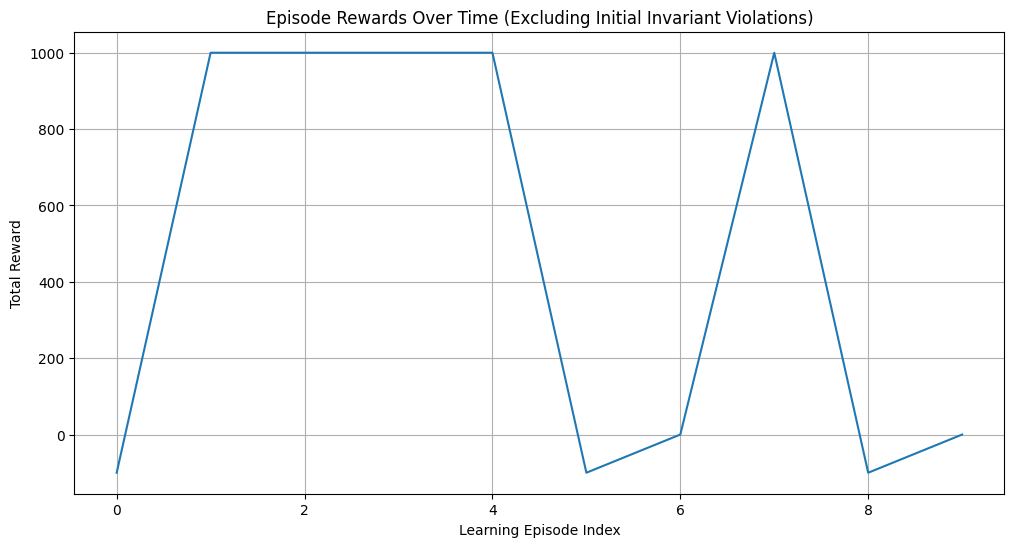

In [ ]:
import gymnasium as gym
from gymnasium import spaces # Import spaces for type checking
import numpy as np
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical, Normal
import os
import matplotlib.pyplot as plt # For plotting learning progress

from pyast_config import SequenceActionConfig, ActionConstraintConfig

# Import the generated environment
from manual_kx_env_for_test_4 import GeneratedKXEnv # Assuming this is the correct module name

# --- Constants for training ---
GAMMA = 0.99  # Discount factor for rewards
LR_ACTOR = 0.0005 # Learning rate for the actor
LR_CRITIC = 0.001 # Learning rate for the critic
CLIP_GRAD_NORM = 0.5 # Gradient clipping to prevent exploding gradients

# --- Neural Network Definitions ---
class Actor(nn.Module):
    def __init__(self, obs_dim, discrete_action_dim, continuous_action_dim):
        super(Actor, self).__init__()
        self.fc1 = nn.Linear(obs_dim, 128)
        self.fc2 = nn.Linear(128, 128)

        self.discrete_action_dim = discrete_action_dim
        self.continuous_action_dim = continuous_action_dim

        # Conditionally create discrete head
        if self.discrete_action_dim > 0:
            self.discrete_head = nn.Linear(128, self.discrete_action_dim)
        else:
            self.discrete_head = None

        # Conditionally create continuous heads
        if self.continuous_action_dim > 0:
            self.continuous_mean_head = nn.Linear(128, self.continuous_action_dim)
            # Initialize log_std to a small negative value
            self.continuous_log_std_head = nn.Parameter(torch.zeros(1, self.continuous_action_dim))
        else:
            self.continuous_mean_head = None
            self.continuous_log_std_head = None

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))

        discrete_logits = None
        continuous_means = None
        continuous_log_stds = None

        if self.discrete_head is not None:
            discrete_logits = self.discrete_head(x)

        if self.continuous_mean_head is not None:
            continuous_means = self.continuous_mean_head(x)
            # Expand log_std to match the batch size and action dimension of means.
            continuous_log_stds = self.continuous_log_std_head.expand_as(continuous_means).clamp(-20, 2)
        
        return discrete_logits, continuous_means, continuous_log_stds

class Critic(nn.Module):
    def __init__(self, obs_dim):
        super(Critic, self).__init__()
        self.fc1 = nn.Linear(obs_dim, 128)
        self.fc2 = nn.Linear(128, 128)
        self.value_head = nn.Linear(128, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.value_head(x)

# --- Learning Agent Definition (A2C-like) ---
class LearningAgent:
    def __init__(self, env, model_dir="models"):
        self.env = env
        self.model_dir = model_dir
        os.makedirs(self.model_dir, exist_ok=True)

        self.obs_dim = env.observation_space.shape[0]

        # Dynamically determine discrete and continuous action dimensions and their keys
        self.discrete_action_dim = 0
        self.continuous_action_dim = 0
        self.discrete_action_key = None
        self.continuous_action_keys = []
        self.continuous_action_component_shapes = {} # To store original shapes for reconstruction

        if isinstance(env.action_space, spaces.Dict):
            for key, space in env.action_space.items():
                if isinstance(space, spaces.Discrete):
                    if self.discrete_action_key is not None:
                        print(f"Warning: Multiple discrete action spaces found. Using the first one identified ('{self.discrete_action_key}').")
                    else:
                        self.discrete_action_dim = space.n
                        self.discrete_action_key = key
                elif isinstance(space, spaces.Box):
                    # Handle scalar Box spaces (shape=()) correctly
                    self.continuous_action_dim += space.shape[0] if space.shape else 1
                    self.continuous_action_component_shapes[key] = space.shape[0] if space.shape else 1
                    self.continuous_action_keys.append(key)
            
            if self.discrete_action_key is None:
                print("Info: No discrete action space found in the environment's action_space Dict.")
            if not self.continuous_action_keys:
                print("Info: No continuous action spaces found in the environment's action_space Dict.")
        else:
            raise TypeError(f"Environment action space is of type {type(env.action_space)}, but LearningAgent expects a gymnasium.spaces.Dict space.")

        if self.discrete_action_dim == 0 and self.continuous_action_dim == 0:
            raise ValueError("Could not determine any action dimensions from the environment's action space. Check its definition.")

        self.actor = Actor(self.obs_dim, self.discrete_action_dim, self.continuous_action_dim)
        self.critic = Critic(self.obs_dim)

        self.actor_optimizer = optim.Adam(self.actor.parameters(), lr=LR_ACTOR)
        self.critic_optimizer = optim.Adam(self.critic.parameters(), lr=LR_CRITIC)

        self.log_probs = []
        self.values = []
        self.rewards = []
        self.masks = []

    def get_action(self, observation):
        obs_tensor = torch.FloatTensor(observation).unsqueeze(0)
        discrete_logits_raw, continuous_means, continuous_log_stds = self.actor(obs_tensor)

        action = {}
        total_log_prob = torch.zeros(1, device=obs_tensor.device) 

        # --- Discrete action sampling ---
        if self.discrete_action_key is not None:
            # Get the control function configuration from the environment
            control_func_config = self.env._control_func_action_config
            
            valid_action_indices = []
            # Need to get the current state from the environment to evaluate constraints
            current_env_state = self.env.state # This is a dictionary
            
            # Evaluate constraints for each discrete action choice
            for i, choice_config in enumerate(control_func_config.choices):
                # Assuming each choice is a SequenceActionConfig and the first action is the constraint
                if isinstance(choice_config, SequenceActionConfig) and choice_config.actions:
                    first_action = choice_config.actions[0]
                    if isinstance(first_action, ActionConstraintConfig):
                        constraint_formula = first_action.formula
                        # Evaluate the constraint using the environment's evaluation logic
                        # Pass current_env_state as local_vars for evaluation
                        is_valid = self.env._evaluate_expression(constraint_formula, local_vars=current_env_state, is_constraint=True)
                        if self.env.debug_mode:
                            print(f"DEBUG_AGENT: Evaluating discrete action {i} constraint '{constraint_formula}'. Result: {is_valid}")
                        if is_valid:
                            valid_action_indices.append(i)
                    else:
                        # If no constraint, assume it's always valid (or handle as a problem)
                        valid_action_indices.append(i)
                else:
                    # If choice_config is not a SequenceActionConfig or has no actions, treat as always valid
                    valid_action_indices.append(i)

            if not valid_action_indices:
                if self.env.debug_mode:
                    print("DEBUG_AGENT: No valid discrete actions found. Choosing action 0 as fallback.")
                # Fallback: if no action is valid, choose action 0. This will likely lead to termination.
                # A more sophisticated agent might have a "do nothing" action or try to learn to avoid this.
                discrete_action = torch.tensor([0], device=obs_tensor.device)
                # Still need to compute log_prob for learning, even if it's a fallback
                discrete_dist = Categorical(logits=discrete_logits_raw[0])
                total_log_prob += discrete_dist.log_prob(discrete_action)
            else:
                # Filter logits to only consider valid actions
                valid_logits = discrete_logits_raw[0, valid_action_indices]
                
                # Create a new categorical distribution from valid logits
                discrete_dist_valid = Categorical(logits=valid_logits)
                
                # Sample an index from the valid actions
                sampled_valid_idx = discrete_dist_valid.sample()
                
                # Map back to the original action index
                discrete_action_original_idx = valid_action_indices[sampled_valid_idx.item()]
                discrete_action = torch.tensor([discrete_action_original_idx], device=obs_tensor.device)
                
                action[self.discrete_action_key] = discrete_action.item()
                
                # Calculate log_prob using the original (unfiltered) distribution
                # This is important for correct policy gradient calculation
                discrete_dist_original = Categorical(logits=discrete_logits_raw[0])
                total_log_prob += discrete_dist_original.log_prob(discrete_action)

        # --- Continuous action sampling ---
        if self.continuous_action_keys:
            continuous_stds = torch.exp(continuous_log_stds)
            continuous_dist = Normal(continuous_means, continuous_stds)
            continuous_actions_tensor = continuous_dist.sample() # Shape: (1, self.continuous_action_dim)
            
            # Calculate log-probability for continuous actions. Sum over the action dimensions.
            total_log_prob += continuous_dist.log_prob(continuous_actions_tensor).sum(dim=-1) # Shape (1,)

            # Assign continuous actions back to their original keys
            current_idx = 0
            for key in self.continuous_action_keys:
                component_size = self.continuous_action_component_shapes[key]
                component_value_tensor = continuous_actions_tensor[0, current_idx : current_idx + component_size]
                
                if component_size == 1:
                    action[key] = np.float64(component_value_tensor.item())
                else:
                    # If a Box space was shape=(N,), then it would be an array.
                    action[key] = component_value_tensor.cpu().numpy().astype(np.float64)
                
                current_idx += component_size
        
        value = self.critic(obs_tensor)
        self.log_probs.append(total_log_prob)
        self.values.append(value)
        
        return action

    def store_transition(self, reward, terminated, truncated):
        self.rewards.append(reward)
        self.masks.append(1.0 - (terminated or truncated))

    def learn(self, next_observation):
        if not self.rewards: # No steps taken in episode, nothing to learn
            return

        log_probs = torch.cat(self.log_probs)
        values = torch.cat(self.values)
        rewards = torch.FloatTensor(self.rewards)
        masks = torch.FloatTensor(self.masks)

        next_obs_tensor = torch.FloatTensor(next_observation).unsqueeze(0)
        next_value = self.critic(next_obs_tensor).detach()

        returns = torch.zeros_like(rewards)
        R = next_value * masks[-1]

        for t in reversed(range(len(rewards))):
            R = rewards[t] + GAMMA * R * masks[t]
            returns[t] = R

        advantages = returns - values.squeeze()

        # --- Actor Loss ---
        actor_loss = -(log_probs * advantages.detach()).mean()
        
        # --- Critic Loss ---
        critic_loss = advantages.pow(2).mean()

        # --- Update Actor Network ---
        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        nn.utils.clip_grad_norm_(self.actor.parameters(), CLIP_GRAD_NORM)
        self.actor_optimizer.step()

        # --- Update Critic Network ---
        self.critic_optimizer.zero_grad()
        critic_loss.backward()
        nn.utils.clip_grad_norm_(self.critic.parameters(), CLIP_GRAD_NORM)
        self.critic_optimizer.step()

        # Clear buffers
        self.log_probs = []
        self.values = []
        self.rewards = []
        self.masks = []

    def save_weights(self, episode_num=None):
        actor_path = os.path.join(self.model_dir, f"actor_weights_ep{episode_num}.pth" if episode_num else "actor_weights_final.pth")
        critic_path = os.path.join(self.model_dir, f"critic_weights_ep{episode_num}.pth" if episode_num else "critic_weights_final.pth")
        torch.save(self.actor.state_dict(), actor_path)
        torch.save(self.critic.state_dict(), critic_path)
        print(f"Saved actor weights to {actor_path}")
        print(f"Saved critic weights to {critic_path}")

    def load_weights(self, episode_num=None):
        actor_path = os.path.join(self.model_dir, f"actor_weights_ep{episode_num}.pth" if episode_num else "actor_weights_final.pth")
        critic_path = os.path.join(self.model_dir, f"critic_weights_ep{episode_num}.pth" if episode_num else "critic_weights_final.pth")
        
        if os.path.exists(actor_path) and os.path.exists(critic_path):
            self.actor.load_state_dict(torch.load(actor_path))
            self.critic.load_state_dict(torch.load(critic_path))
            print(f"Loaded weights from episode {episode_num if episode_num else 'final'}.")
            return True
        else:
            print(f"No weights found at {actor_path} and {critic_path}. Starting from scratch.")
            return False

# --- Environment Setup and Testing ---

# --- Configuration for Training ---
num_episodes = 100       # Total number of episodes to run
max_steps_per_episode = 30  # Maximum steps before an episode is truncated
SAVE_INTERVAL = 100          # Save weights every X episodes
LOAD_EXISTING_WEIGHTS = False # Set to True to resume training from previously saved 'final' weights
EVALUATE_ONLY = False        # Set to True to run without learning, using loaded weights (if any)

# Instantiate the environment once for both initial info and training
# Pass debug_mode=True to the environment for detailed termination status
env = GeneratedKXEnv(debug_mode=False) # <--- Set debug_mode to True

# --- Initial Environment Information ---
observation, info = env.reset()
print("--- Environment Information ---")
print(f"Initial observation: {observation}")
print(f"Observation Space: {env.observation_space}")
print(f"Action Space: {env.action_space}") # This will now show the actual action space structure
print(f"Initial State Info: {env._get_info()}")

# Removed redundant setting of constants.
# The constants (A, b, ep) are already fixed in GeneratedKXEnv.__init__
# and GDelta, Vmax are sampled by CISB based on their metadata bounds.
# The 'W' constant is not defined in the environment's config and is not used.
# print(f"Environment Constants Set: W={env.constants['W']}, A={env.constants['A']}, b={env.constants['b']}, ep={env.constants['ep']}")


# --- Training / Testing with LearningAgent ---
print("\n--- Training with LearningAgent ---")

agent = LearningAgent(env) 

# Load weights if configured to do so
if LOAD_EXISTING_WEIGHTS or EVALUATE_ONLY:
    agent.load_weights()

total_steps_taken = 0
episode_rewards = [] # To track learning progress over episodes

for episode in range(num_episodes):
    observation, info = env.reset()
    
    # Removed redundant re-setting of constants after reset.
    # The constants are correctly handled by the environment's reset from CISB.
    # env.constants['W'] = 1.0
    # env.constants['A'] = 1.0
    # env.constants['b'] = 0.5
    # env.constants['ep'] = 1.0
    
    episode_reward = 0.0
    episode_steps = 0
    ignore_episode_for_learning = False # Flag to ignore episodes with initial invariant violations
    
    for step in range(max_steps_per_episode):
        action = agent.get_action(observation) 
        
        next_observation, reward, terminated, truncated, info = env.step(action)
        
        episode_steps += 1
        
        # Check for initial state invariant violation only after the first step
        # This ensures we don't check `info` from `env.reset()` which might not have `termination_status`
        if (terminated or truncated) and episode_steps == 1:
            termination_status = info.get('termination_status')
            if termination_status in ['invariant_violation', 'general_pre_control_invariant_violation']:
                print(f"Episode {episode + 1} terminated immediately due to initial state invariant violation (status: {termination_status}). Ignoring this episode for learning.")
                ignore_episode_for_learning = True
        
        # Only store transition if not evaluating and not ignoring the episode for learning
        if not EVALUATE_ONLY and not ignore_episode_for_learning:
            agent.store_transition(reward, terminated, truncated)
        
        observation = next_observation
        episode_reward += reward
        total_steps_taken += 1
        
        if terminated or truncated:
            break
    
    # Only call learn if not evaluating and not ignoring the episode
    if not EVALUATE_ONLY and not ignore_episode_for_learning:
        agent.learn(observation) 
    
    # Only append reward if not ignoring the episode for learning,
    # otherwise the average reward will be skewed by 0-reward ignored episodes.
    if not ignore_episode_for_learning:
        episode_rewards.append(episode_reward)
    
    avg_reward_last_100 = np.mean(episode_rewards[-100:]) if episode_rewards else 0.0
    print(f"Episode {episode + 1}/{num_episodes}, Steps: {episode_steps}, Total Reward: {episode_reward:.2f}, Avg Reward (last 100): {avg_reward_last_100:.2f}")

    if (episode + 1) % SAVE_INTERVAL == 0 and not EVALUATE_ONLY:
        agent.save_weights(episode + 1)

if not EVALUATE_ONLY:
    agent.save_weights()

env.close()

print("\n--- Simulation Summary ---")
print(f"Total Episodes Run: {num_episodes}")
print(f"Total Steps Across All Episodes: {total_steps_taken}")
if episode_rewards:
    print(f"Average Reward over last 100 *learning* episodes: {np.mean(episode_rewards[-100:]):.2f}")
    print(f"Max Reward achieved in *learning* episodes: {np.max(episode_rewards):.2f}")
else:
    print("No learning episodes completed to calculate average/max rewards.")


if episode_rewards:
    plt.figure(figsize=(12, 6))
    plt.plot(episode_rewards)
    plt.title('Episode Rewards Over Time (Excluding Initial Invariant Violations)')
    plt.xlabel('Learning Episode Index') # Changed label to reflect only learning episodes
    plt.ylabel('Total Reward')
    plt.grid(True)
    plt.show()

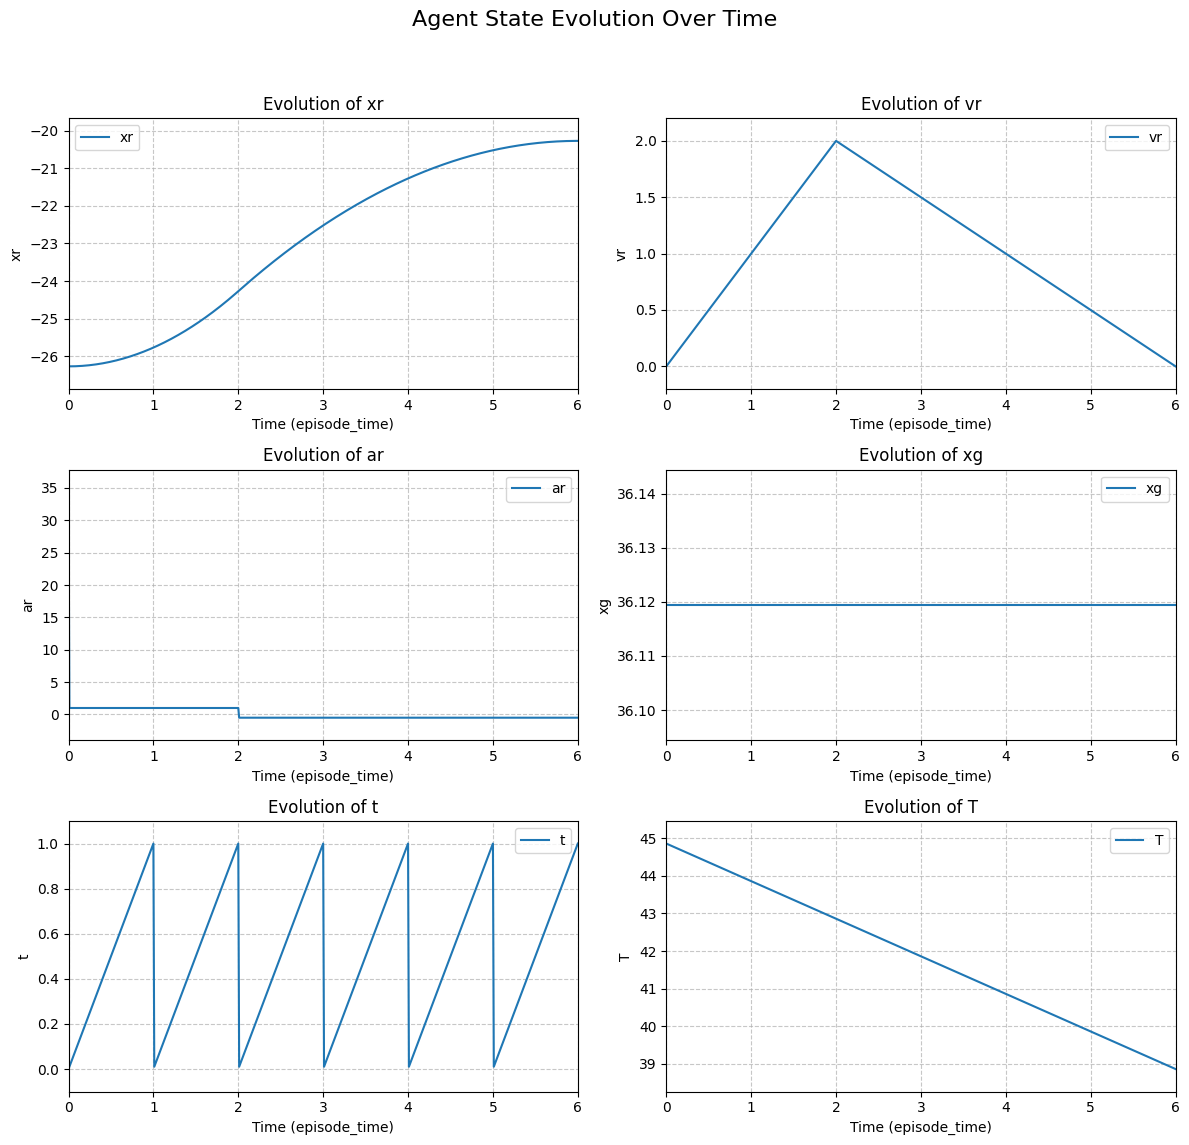

In [2]:
env.render(mode="matplotlib")